# Genre and recorded price

Run all cells. The first code cell loads the preparation notebook into this kernel, so this notebook can start from a fresh session. Put `games.csv` beside the notebooks first.


In [1]:
%%capture
%run ./01_data_loading.ipynb


## 1. Genre-by-price heatmap (100+ reviews)

Use `indie_focus_reviewed_df`: Indie-labelled entries released January 1, 2019 through December 25, 2025 inclusive, with at least 100 recorded reviews and the agreed product/title/zero-price exclusions. Use the revised price groups, including a separate zero-price + Free To Play-labelled reference group.

Each cell shows the median entry-level positive-review percentage and number of entries. Genre labels overlap. Omit the redundant Indie row and the agreed excluded Nudity, Sexual Content, Gore, Violent, and Free To Play rows; retain the games under other labels. Early Access remains a status label. Show small observed cells with * when n < 30 rather than suppressing them. Gray cells have no qualifying entries. This is the current 2019–2025 Indie analysis scope.

In [2]:
focus_genre_df = indie_focus_reviewed_df.copy()
focus_genre_df["genre"] = focus_genre_df["Genres"].fillna("").str.split(",")
focus_genre_df = focus_genre_df.explode("genre")
focus_genre_df["genre"] = focus_genre_df["genre"].str.strip()

excluded_focus_labels = {
    "Indie", "Nudity", "Sexual Content", "Gore", "Violent", "Free To Play",
}
focus_genre_df = focus_genre_df.loc[
    focus_genre_df["genre"].ne("")
    & ~focus_genre_df["genre"].isin(excluded_focus_labels)
].drop_duplicates(["AppID", "genre"]).copy()

focus_genre_price_summary = focus_genre_df.groupby(
    ["genre", "price_group"], observed=True
).agg(
    entries=("AppID", "size"),
    median_positive_pct=("positive_share", lambda values: values.median() * 100),
)
focus_genre_counts = focus_genre_price_summary["entries"].unstack("price_group")
focus_genre_reception_display = (
    focus_genre_price_summary["median_positive_pct"]
    .unstack("price_group")
    .dropna(how="all")
    .dropna(axis=1, how="all")
    .round(1)
)

focus_genre_reception_display

price_group,0 (F2P label),"(0, 5]","(5, 10]","(10, 15]","(15, 20]","(20, 30]",Above 30
genre,,,,,,,
Action,81.3,83.1,86.6,85.8,81.8,80.8,87.0
Adventure,84.7,85.3,87.3,86.8,84.7,86.2,85.0
Casual,85.8,87.2,88.5,88.6,88.1,88.9,77.6
Early Access,76.4,79.1,85.1,83.6,83.6,81.2,77.7
Massively Multiplayer,69.0,71.8,75.4,70.2,74.7,79.5,76.3
RPG,80.2,82.9,85.5,83.3,85.3,84.3,76.3
Racing,81.8,84.1,86.3,88.5,85.8,84.1,87.3
Simulation,82.1,82.9,85.0,84.0,82.6,85.8,83.8
Sports,78.9,86.2,86.6,86.4,78.4,85.9,81.9


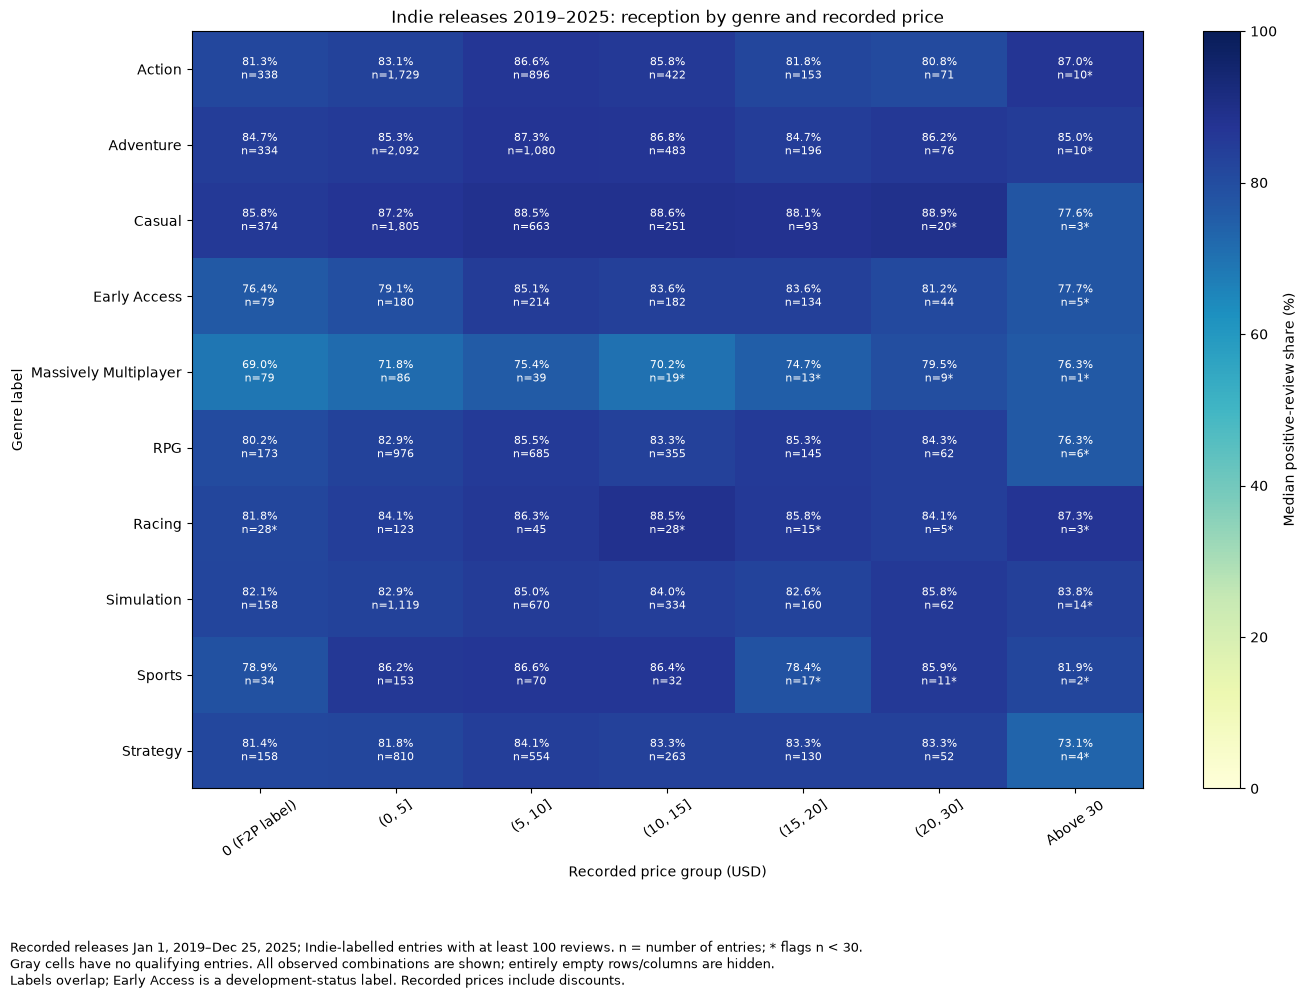

In [3]:
import matplotlib.pyplot as plt

focus_heatmap_data = focus_genre_reception_display.copy()
values = np.ma.masked_invalid(focus_heatmap_data.to_numpy(dtype=float))
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#eeeeee")

fig, ax = plt.subplots(figsize=(14, 10))
image = ax.imshow(values, cmap=cmap, vmin=0, vmax=100, aspect="auto")
fig.colorbar(image, ax=ax, label="Median positive-review share (%)")

ax.set_xticks(range(len(focus_heatmap_data.columns)), focus_heatmap_data.columns.astype(str))
row_labels = [
    "Free To Play (zero price)" if label == "Free To Play" else label
    for label in focus_heatmap_data.index
]
ax.set_yticks(range(len(focus_heatmap_data.index)), row_labels)
ax.tick_params(axis="x", rotation=35)

for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        if not np.ma.is_masked(values[row, col]):
            value = float(values[row, col])
            count = int(focus_genre_counts.loc[
                focus_heatmap_data.index[row], focus_heatmap_data.columns[col]
            ])
            flag = "*" if count < 30 else ""
            ax.text(col, row, f"{value:.1f}%\nn={count:,}{flag}",
                    ha="center", va="center",
                    color="white" if value >= 65 else "black", fontsize=8)

ax.set(title="Indie releases 2019–2025: reception by genre and recorded price",
       xlabel="Recorded price group (USD)", ylabel="Genre label")
fig.text(0.01, 0.01,
         "Recorded releases Jan 1, 2019–Dec 25, 2025; Indie-labelled entries with at least 100 reviews. n = number of entries; * flags n < 30.\n"
         "Gray cells have no qualifying entries. All observed combinations are shown; entirely empty rows/columns are hidden.\n"
         "Labels overlap; Early Access is a development-status label. Recorded prices include discounts.",
         fontsize=9)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()